In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
clients_demo = pd.read_csv("02_cleaned_data_files/cleaned_clients_demographics.csv")
clients_var = pd.read_csv("02_cleaned_data_files/cleaned_clients_variation.csv")
web_events = pd.read_csv("02_cleaned_data_files/cleaned_web_events.csv")
vanguard_tableau = pd.read_csv("vanguard_tableau.csv")

In [3]:
web_events.head()

,client_id,visitor_id,visit_id,process_step,date_time
0,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:27:07
1,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:26:51
2,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:19:22
3,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:19:13
4,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:18:04


In [4]:
# Check available process steps
print(web_events['process_step'].value_counts(dropna=False))

# Check datetime column type
print("\nDate type:")
print(web_events['date_time'].dtype)

# Check unique visits
print("\nUnique visits:")
print(web_events['visit_id'].nunique())

process_step
start      101119
step_1      68186
step_2      56654
step_3      48252
confirm     42924
Name: count, dtype: int64

Date type:
str

Unique visits:
69185


In [5]:
# Convert timestamps to datetime
web_events['date_time'] = pd.to_datetime(
    web_events['date_time'],
    errors='coerce'
)

# Check the result
print("Data type:", web_events['date_time'].dtype)
print("Invalid dates:", web_events['date_time'].isna().sum())
print("First date:", web_events['date_time'].min())
print("Last date:", web_events['date_time'].max())

Data type: datetime64[us]
Invalid dates: 0
First date: 2017-03-15 00:19:28
Last date: 2017-06-20 23:57:06


In [6]:
# Check duplicate client IDs
print("Duplicate IDs:", clients_var['client_id'].duplicated().sum())

# Check experiment groups
print(clients_var['Variation'].value_counts(dropna=False))

Duplicate IDs: 0
Variation
Test       26961
Control    23527
Name: count, dtype: int64


In [7]:
# Select only Test and Control clients
ab_clients = clients_var[
    clients_var['Variation'].isin(['Test', 'Control'])
]

# Merge web events with experiment groups
web_ab = web_events.merge(
    ab_clients,
    on='client_id',
    how='inner'
)

# Check the result
print(web_ab.shape)
print(web_ab['Variation'].value_counts())

(317135, 6)
Variation
Test       176641
Control    140494
Name: count, dtype: int64


In [8]:
# Sort events by client, visit and time
web_ab = web_ab.sort_values(
    by=['client_id', 'visit_id', 'date_time']
)

# Check the result
web_ab[['client_id', 'visit_id', 'process_step', 'date_time']].head(15)

,client_id,visit_id,process_step,date_time
70411,555,637149525_38041617439_716659,start,2017-04-15 12:57:56
70410,555,637149525_38041617439_716659,step_1,2017-04-15 12:58:03
70409,555,637149525_38041617439_716659,step_2,2017-04-15 12:58:35
70408,555,637149525_38041617439_716659,step_3,2017-04-15 13:00:14
70407,555,637149525_38041617439_716659,confirm,2017-04-15 13:00:34
135189,647,40369564_40101682850_311847,start,2017-04-12 15:41:28
135188,647,40369564_40101682850_311847,step_1,2017-04-12 15:41:35
135187,647,40369564_40101682850_311847,step_2,2017-04-12 15:41:53
135186,647,40369564_40101682850_311847,step_3,2017-04-12 15:45:02
135183,647,40369564_40101682850_311847,confirm,2017-04-12 15:47:45


In [9]:
# Get the timestamp of the next event within each visit
web_ab['next_time'] = web_ab.groupby(
    ['client_id', 'visit_id']
)['date_time'].shift(-1)

# Calculate time spent in seconds
web_ab['time_spent_sec'] = (
    web_ab['next_time'] - web_ab['date_time']
).dt.total_seconds()

# Check the result
web_ab[
    ['client_id', 'process_step', 'date_time',
     'next_time', 'time_spent_sec']
].head(15)

,client_id,process_step,date_time,next_time,time_spent_sec
70411,555,start,2017-04-15 12:57:56,2017-04-15 12:58:03,7.0
70410,555,step_1,2017-04-15 12:58:03,2017-04-15 12:58:35,32.0
70409,555,step_2,2017-04-15 12:58:35,2017-04-15 13:00:14,99.0
70408,555,step_3,2017-04-15 13:00:14,2017-04-15 13:00:34,20.0
70407,555,confirm,2017-04-15 13:00:34,NaT,NaN
135189,647,start,2017-04-12 15:41:28,2017-04-12 15:41:35,7.0
135188,647,step_1,2017-04-12 15:41:35,2017-04-12 15:41:53,18.0
135187,647,step_2,2017-04-12 15:41:53,2017-04-12 15:45:02,189.0
135186,647,step_3,2017-04-12 15:45:02,2017-04-12 15:47:45,163.0
135183,647,confirm,2017-04-12 15:47:45,NaT,NaN


In [10]:
# Check time distribution
print(web_ab['time_spent_sec'].describe().round(2))

# Check unusually long intervals (over 30 minutes)
print("\nOver 30 minutes:",
      (web_ab['time_spent_sec'] > 1800).sum())

# Check zero and negative intervals
print("Zero seconds:",
      (web_ab['time_spent_sec'] == 0).sum())

print("Negative seconds:",
      (web_ab['time_spent_sec'] < 0).sum())

count    247708.00
mean         83.87
std         214.08
min           0.00
25%          13.00
50%          36.00
75%          82.00
max       40235.00
Name: time_spent_sec, dtype: float64

Over 30 minutes: 349
Zero seconds: 528
Negative seconds: 0


In [11]:
# Keep valid time intervals (maximum 30 minutes)
web_time = web_ab[
    web_ab['time_spent_sec'].between(0, 1800) &
    (web_ab['process_step'] != 'confirm')
]

# Calculate average and median time per step
step_time = (
    web_time.groupby(['process_step', 'Variation'])
    ['time_spent_sec']
    .agg(['mean', 'median', 'count'])
    .round(1)
)

print(step_time)

                         mean  median  count
process_step Variation                      
start        Control     60.9    20.0  35658
             Test        56.3    14.0  46219
step_1       Control     47.5    20.0  26009
             Test        58.5    27.0  35485
step_2       Control     90.2    64.0  24295
             Test        88.1    61.0  29561
step_3       Control    133.3    72.0  20245
             Test       124.8    57.0  23932


In [12]:
# Compare average time between Test and Control
time_comparison = step_time['mean'].unstack()

# Calculate percentage difference
time_comparison['difference_%'] = (
    (time_comparison['Test'] - time_comparison['Control'])
    / time_comparison['Control'] * 100
).round(1)

print(time_comparison)

Variation     Control   Test  difference_%
process_step                              
start            60.9   56.3          -7.6
step_1           47.5   58.5          23.2
step_2           90.2   88.1          -2.3
step_3          133.3  124.8          -6.4


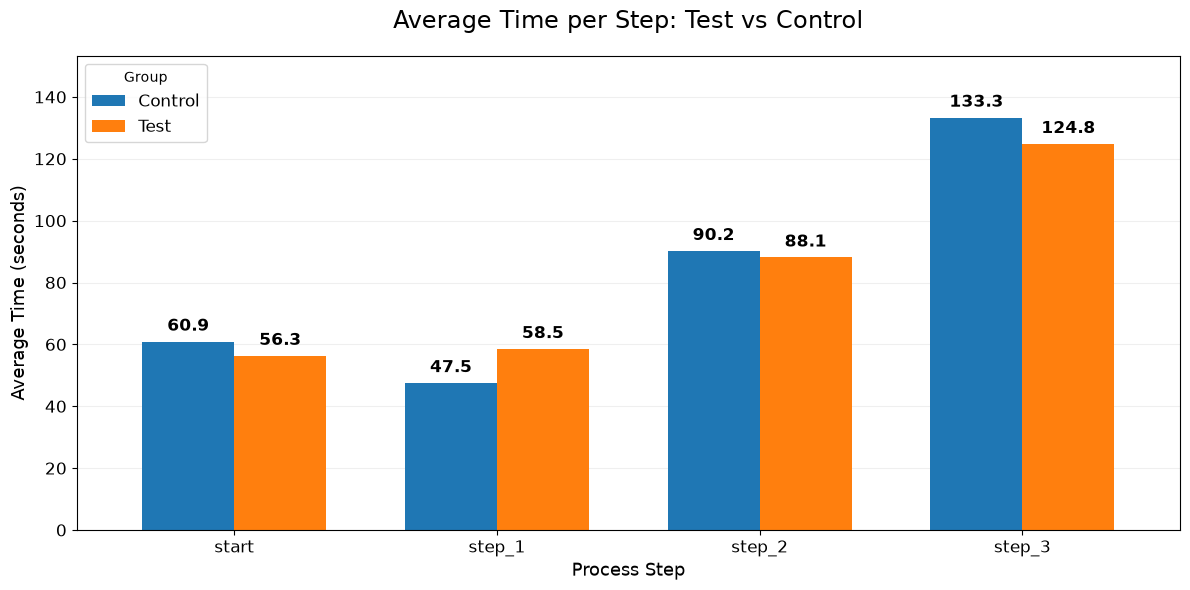

In [13]:
# Prepare data for visualization
time_plot = step_time['mean'].unstack()

# Create grouped bar chart
ax = time_plot.plot(kind='bar', figsize=(12, 6), width=0.7)

# Add values above bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f',
        padding=5,
        fontsize=12,
        fontweight='bold'
    )

# Titles and labels
plt.title('Average Time per Step: Test vs Control', fontsize=17, pad=20)
plt.xlabel('Process Step', fontsize=13)
plt.ylabel('Average Time (seconds)', fontsize=13)

# Formatting
plt.xticks(rotation=0, fontsize=12)
plt.yticks(fontsize=12)
plt.legend(title='Group', fontsize=12)

# Grid and spacing
ax.set_axisbelow(True)
plt.grid(axis='y', alpha=0.2)
plt.ylim(0, time_plot.max().max() * 1.15)

plt.tight_layout()
plt.show()

##### The redesigned interface shows mixed performance. Test users complete three of four measured steps faster, but spend 23.5% more time on Step 1. This suggests a potential usability bottleneck that requires further investigation.

--- 

##### Prepearing for Tableau

In [15]:
# Columns identifying each event
#keys = [
#   "client_id", "visitor_id", "visit_id",
#    "process_step", "date_time"
#]

# Ensure matching datetime types
#vanguard_tableau["date_time"] = pd.to_datetime(vanguard_tableau["date_time"])
#web_ab["date_time"] = pd.to_datetime(web_ab["date_time"])

# Add time spent to our Tableau dataset
#vanguard_tableau = vanguard_tableau.merge(
#    web_ab[keys + ["time_spent_sec"]],
#    on=keys,
#    how="left",
#    validate="one_to_one",
#    indicator=True
#)

# Check merge results
#print(vanguard_tableau["_merge"].value_counts())
#print("Total rows:", len(vanguard_tableau))

In [16]:
# Remove temporary merge column
# vanguard_tableau = vanguard_tableau.drop(columns="_merge")

# Save updated dataset
#vanguard_tableau.to_csv("vanguard_tableau.csv", index=False)

print("Rows:", len(vanguard_tableau))
print("Columns:", vanguard_tableau.columns.tolist())

Rows: 317135
Columns: ['client_id', 'visitor_id', 'visit_id', 'process_step', 'date_time', 'Variation', 'clnt_tenure_yr', 'clnt_tenure_mnth', 'clnt_age', 'gendr', 'num_accts', 'bal', 'calls_6_mnth', 'logons_6_mnth', 'age_group', 'completed', 'time_spent_sec_x', 'is_error', 'time_spent_sec_y', '_merge']
